# Actividad 5. Entrenamiento, ajuste y registro de modelos con MLflow

Clasificación de enfermedades foliares de maíz en **fotos de parcela**: regresión logística frente a random forest sobre 1,280 características de MobileNetV2, con Grid Search, validación cruzada agrupada y registro en MLflow.

El pipeline vive en `fuentes/` (`obtener_datos.py`, `datos_prep.py`, `train.py`); este notebook lo llama y analiza los resultados:

1. Datos: limpieza y visualizaciones para detectar patrones y anomalías
2. Diseño del entrenamiento
3. Resultados registrados en MLflow
4. Comparación estadística y evaluación por sesión de captura
5. Deuda técnica

Corre localmente (desde la raíz del repositorio o desde `fuentes/`) o en Colab: la primera celda clona el repositorio si no lo encuentra.

In [1]:
import os, subprocess, sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")   # barra de progreso de huggingface_hub sin ipywidgets

REENTRENAR = False   # True: descarga las imágenes, limpia, extrae características y entrena de nuevo (~15 min en CPU)
REPO_GIT = "https://github.com/RabindranathMunozPacheco/Actividad-5.git"

if "google.colab" in sys.modules and not Path("Actividad-5").exists():     # Colab: clonar e instalar
    subprocess.run(["git", "clone", "-q", REPO_GIT], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "Actividad-5/requirements.txt"], check=True)
RAIZ = next(p for p in (Path.cwd(), Path.cwd().parent, Path.cwd() / "Actividad-5")
            if (p / "fuentes" / "train.py").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "fuentes"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

DATOS_LIMP = RAIZ / "datos" / "datos_limp"
FIGURAS = RAIZ / "evidencias" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
ORDEN = ["Sana", "Mancha gris", "Tizón", "Roya común"]
COLOR = {"Sana": "#4caf50", "Mancha gris": "#607d8b", "Tizón": "#ff9800", "Roya común": "#b71c1c"}


def guardar(fig, nombre):
    """Guarda la figura en evidencias/figuras/ (la usa el README) y la muestra."""
    fig.savefig(FIGURAS / nombre, dpi=120, bbox_inches="tight")
    plt.show()


def correr(script):
    salida = subprocess.run([sys.executable, f"fuentes/{script}"], capture_output=True, text=True, encoding="utf-8")
    print(salida.stdout[-2500:])
    salida.check_returncode()


if REENTRENAR:
    for script in ("obtener_datos.py", "datos_prep.py", "train.py"):
        correr(script)
print(f"Raíz del repositorio: {RAIZ.name}/")

Raíz del repositorio: Actividad5/


## 1. Datos

Origen: repositorio de campo [`muAtarist/maize_foliar_diseases`](https://huggingface.co/datasets/muAtarist/maize_foliar_diseases) en un commit fijo. `datos_prep.py` aplica 8 reglas en orden (criterios y conteos en el README, sección 3) y deja en `datos/datos_limp/` el registro de cada imagen, el dataset limpio y sus características.

In [2]:
manifiesto = pd.read_csv(RAIZ / "datos" / "datos_ini" / "manifiesto.csv")
registro = pd.read_csv(DATOS_LIMP / "registro_limpieza.csv")
limpio = pd.read_csv(DATOS_LIMP / "maiz_parcela.csv")
caract = pd.read_parquet(DATOS_LIMP / "caracteristicas.parquet")
referencia = pd.read_parquet(DATOS_LIMP / "referencia_plantvillage.parquet")
COLS = [c for c in caract.columns if c.startswith("f")]
print(f"Origen: {len(manifiesto):,} imágenes | limpio: {len(limpio):,} fotos x {len(COLS):,} características | "
      f"{limpio['sesion'].nunique()} sesiones, {limpio['grupo'].nunique():,} grupos")
limpio.head(3)

Origen: 7,012 imágenes | limpio: 1,078 fotos x 1,280 características | 13 sesiones, 1,039 grupos


,id,ruta,archivo,sha256,etiqueta_original,clase,sesion,grupo,modo_original,tamano_original
0,m0000,train/CommonRust/104_2019-03-13--Cedara-DKB-DS...,104_2019-03-13--Cedara-DKB-DSC_0308_CR.jpg,cdce83c8e260358a13c469ec6de5eb5906ef14d6e63ebb...,CommonRust,Roya común,20190313,0,RGB,"(224, 224)"
1,m0001,train/CommonRust/10_2019-03-13--Cedara-DKB-DSC...,10_2019-03-13--Cedara-DKB-DSC_0300_CR.jpg,5275abf28d30d94cb4b4f96f85e15a0d8600200a80d507...,CommonRust,Roya común,20190313,1,RGB,"(224, 224)"
2,m0002,train/CommonRust/111_2019-03-13--Cedara-DKB-DS...,111_2019-03-13--Cedara-DKB-DSC_0214_CR.jpg,6c2abcc7037529cb575b25f7c944f0fdfb8f211c02703a...,CommonRust,Roya común,20190313,2,RGB,"(224, 224)"


### 1.1 Registro de limpieza

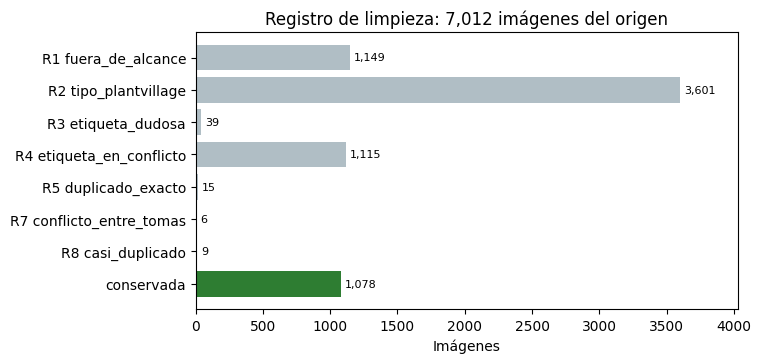

In [3]:
conteo = registro["regla"].value_counts()
orden = sorted(conteo.index, key=lambda r: (r == "conservada", r))[::-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(orden, conteo[orden], color=["#2e7d32" if r == "conservada" else "#b0bec5" for r in orden])
for i, r in enumerate(orden):
    ax.text(conteo[r] + 30, i, f"{conteo[r]:,}", va="center", fontsize=8)
ax.set(title=f"Registro de limpieza: {len(registro):,} imágenes del origen", xlabel="Imágenes", xlim=(0, conteo.max() * 1.12))
guardar(fig, "datos_1_limpieza.png")

**Lectura.** De 7,012 imágenes quedan 1,078 (15 %). La exclusión más grande es R2: 3,601 imágenes tipo PlantVillage (51 % del origen), una colección distinta (casi siempre una hoja aislada en primer plano y muchas sobre fondo uniforme) que no representa lo que verá la app. Le sigue R4 con 1,115 fotos que están en más de una carpeta. Las reglas que miran la imagen (R7 y R8) solo quitan 15 fotos: el origen casi no tenía tomas repetidas, pero sí tenía muchas copias del mismo archivo con distinta etiqueta.

### 1.2 Clases antes y después de la limpieza

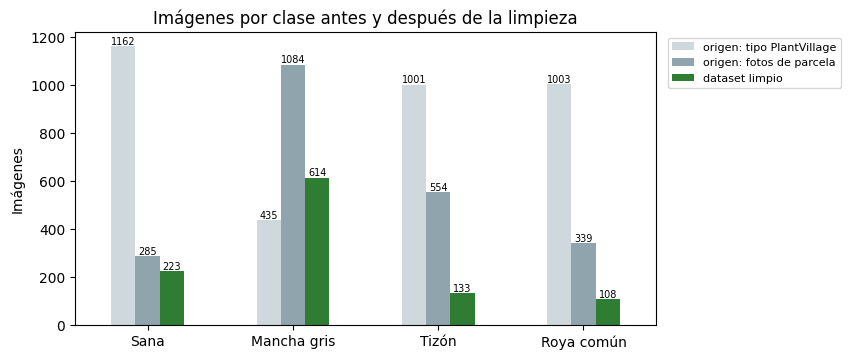

,origen: tipo PlantVillage,origen: fotos de parcela,dataset limpio
clase,,,
Sana,1162,285,223
Mancha gris,435,1084,614
Tizón,1001,554,133
Roya común,1003,339,108


In [4]:
CARPETA_CLASE = {"CornLeafBlight": "Tizón", "CommonRust": "Roya común", "GreyLeafSpot": "Mancha gris",
                 "NoFoliarSymptoms": "Sana", "PhaeosphaeriaLeafSpot": "Phaeosphaeria", "UnidentifiedDisease": "No identificada"}
caso = registro[registro["carpeta"].map(CARPETA_CLASE).isin(ORDEN)].assign(clase=lambda d: d["carpeta"].map(CARPETA_CLASE))
es_pv = caso["archivo"].str.startswith("Corn_")
tabla = pd.DataFrame({"origen: tipo PlantVillage": caso[es_pv]["clase"].value_counts(),
                      "origen: fotos de parcela": caso[~es_pv]["clase"].value_counts(),
                      "dataset limpio": limpio["clase"].value_counts()}).loc[ORDEN]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
tabla.plot.bar(ax=ax, rot=0, color=["#cfd8dc", "#90a4ae", "#2e7d32"])
for barras in ax.containers:
    ax.bar_label(barras, fontsize=7)
ax.set(title="Imágenes por clase antes y después de la limpieza", ylabel="Imágenes", xlabel="")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
guardar(fig, "datos_2_clases.png")
tabla

**Lectura.** En el origen las cuatro clases parecen balanceadas (1,342 a 1,555 imágenes por carpeta), pero ese balance lo ponen las imágenes `Corn_*`. En las fotos de parcela, Mancha gris domina, y después de limpiar queda un desbalance de 5.7 a 1 entre Mancha gris (614) y Roya común (108). Tizón es la clase que más pierde: de 554 fotos de parcela quedan 133 (−76 %), porque es la enfermedad que más aparece junto con otras en la misma hoja (ver 1.3). Ese desbalance justifica usar F1 macro y probar `class_weight` en el Grid Search.

### 1.3 La misma foto en varias carpetas (etiquetas en conflicto)

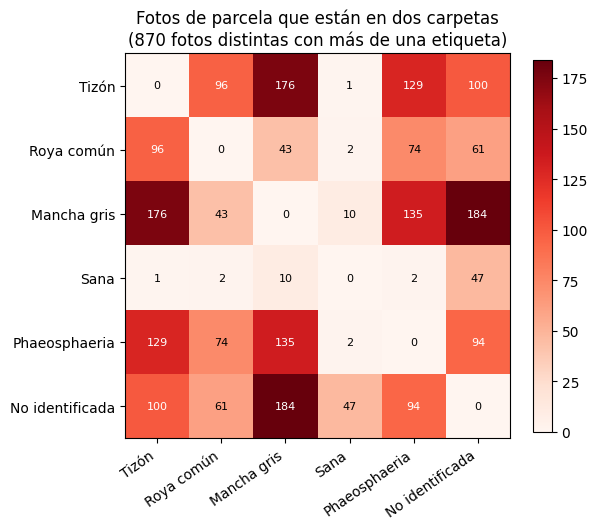

In [5]:
parcela = manifiesto[~manifiesto["archivo"].str.startswith("Corn_")]
carpetas_por_foto = parcela.groupby("sha256")["carpeta"].agg(lambda s: sorted(set(s)))
multiples = carpetas_por_foto[carpetas_por_foto.map(len) > 1]
nombres = [CARPETA_CLASE[c] for c in CARPETA_CLASE]
matriz = pd.DataFrame(0, index=nombres, columns=nombres)
for carpetas in multiples:
    for a in carpetas:
        for b in carpetas:
            if a != b:
                matriz.loc[CARPETA_CLASE[a], CARPETA_CLASE[b]] += 1
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(matriz.values, cmap="Reds")
ax.set_xticks(range(6), nombres, rotation=35, ha="right")
ax.set_yticks(range(6), nombres)
for i in range(6):
    for j in range(6):
        v = matriz.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > matriz.values.max() / 2 else "black")
ax.set_title(f"Fotos de parcela que están en dos carpetas\n({len(multiples)} fotos distintas con más de una etiqueta)")
fig.colorbar(im, ax=ax, fraction=0.04)
guardar(fig, "datos_3_conflictos.png")

**Lectura.** 870 fotos distintas de parcela están copiadas en dos o más carpetas. Las parejas más frecuentes son Mancha gris con enfermedad no identificada (184), Mancha gris con Tizón (176) y Mancha gris con Phaeosphaeria (135). Son hojas con varias enfermedades a la vez que el autor puso en cada carpeta. Si se dejan, el modelo recibe la misma foto con dos etiquetas distintas y ninguna es incorrecta, así que no hay una respuesta que aprender. "Sana" casi no se cruza con las enfermedades del caso, pero 47 fotos sanas también están como enfermedad no identificada. Esto cambia la lectura de la Actividad 4: el F1 de 0.41 en fotos de parcela se midió con estas etiquetas múltiples, así que parte de ese error venía de las etiquetas y no del modelo.

### 1.4 Sesión de captura y clase

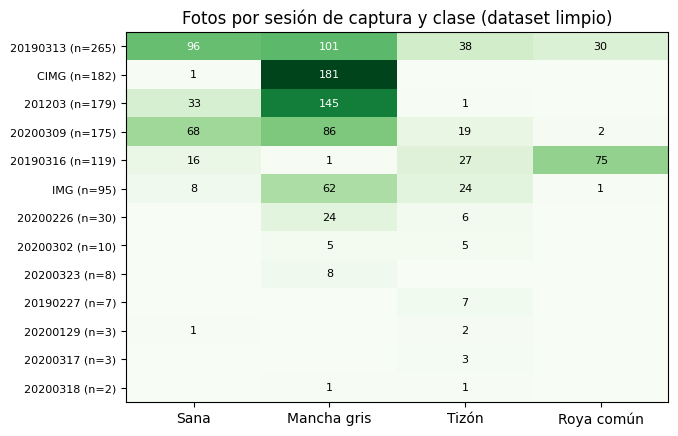

Proporción de cada clase que viene de su sesión principal:
clase
Sana           0.43
Mancha gris    0.29
Tizón          0.29
Roya común     0.69


In [6]:
sesion_clase = pd.crosstab(limpio["sesion"], limpio["clase"])[ORDEN]
sesion_clase = sesion_clase.loc[sesion_clase.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.imshow(sesion_clase.values, cmap="Greens", aspect="auto")
ax.set_xticks(range(4), ORDEN)
ax.set_yticks(range(len(sesion_clase)), [f"{s} (n={n})" for s, n in sesion_clase.sum(axis=1).items()], fontsize=8)
for i in range(len(sesion_clase)):
    for j in range(4):
        v = sesion_clase.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8, color="white" if v > 90 else "black")
ax.set_title("Fotos por sesión de captura y clase (dataset limpio)")
guardar(fig, "datos_4_sesion_clase.png")
print("Proporción de cada clase que viene de su sesión principal:")
print((sesion_clase.max() / sesion_clase.sum()).round(2).to_string())

**Lectura.** La sesión de captura y la clase están muy mezcladas. La cámara `CIMG` tomó 182 fotos y 181 son de Mancha gris. La sesión `201203` es 81 % Mancha gris. El 16 de marzo de 2019 (`20190316`) concentra 75 de las 108 fotos de Roya (69 %). Un modelo puede aprender la luz, el fondo o la cámara de cada sesión en lugar de la lesión, y la validación cruzada aleatoria no lo detecta porque reparte fotos de cada sesión entre entrenamiento y validación. Por eso, además de la validación por grupos, se evalúa dejando fuera sesiones completas (sección 4).

### 1.5 Espacio de características: origen, clase y sesión

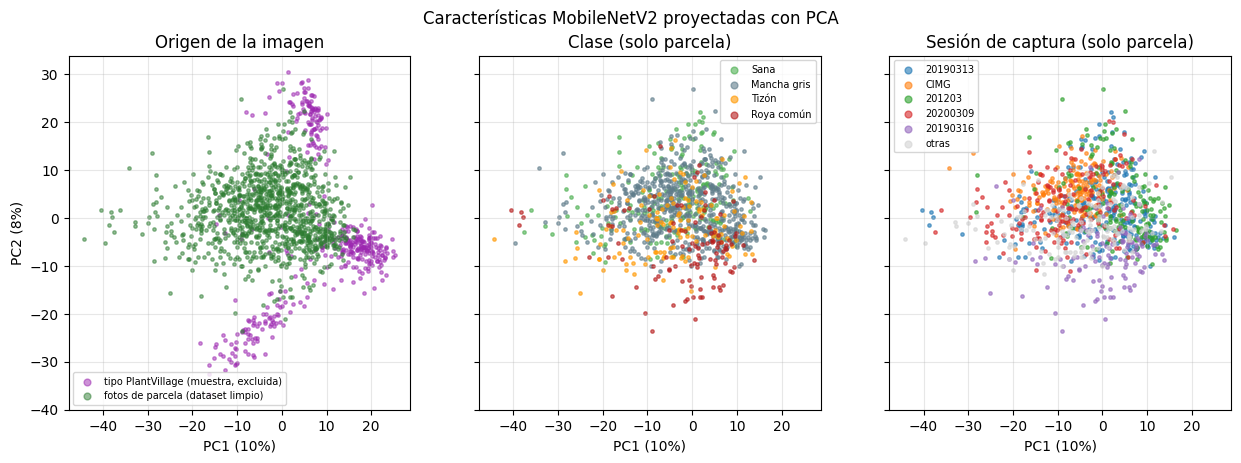

Vecinos con la misma clase: 64% (al azar 39%, 1.6 veces)
Vecinos con la misma sesion: 62% (al azar 16%, 3.8 veces)


In [7]:
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

escala = StandardScaler().fit(np.vstack([caract[COLS].values, referencia[COLS].values]))
pca = PCA(n_components=2, random_state=42).fit(escala.transform(np.vstack([caract[COLS].values, referencia[COLS].values])))
z_parcela = pca.transform(escala.transform(caract[COLS].values))
z_pv = pca.transform(escala.transform(referencia[COLS].values))
var = pca.explained_variance_ratio_

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
axs[0].scatter(*z_pv.T, s=6, c="#9c27b0", alpha=0.5, label="tipo PlantVillage (muestra, excluida)")
axs[0].scatter(*z_parcela.T, s=6, c="#2e7d32", alpha=0.5, label="fotos de parcela (dataset limpio)")
axs[0].set_title("Origen de la imagen")
for clase in ORDEN:
    m = (limpio["clase"] == clase).to_numpy()
    axs[1].scatter(*z_parcela[m].T, s=6, c=COLOR[clase], alpha=0.6, label=clase)
axs[1].set_title("Clase (solo parcela)")
principales = limpio["sesion"].value_counts().index[:5]
for s in principales:
    m = (limpio["sesion"] == s).to_numpy()
    axs[2].scatter(*z_parcela[m].T, s=6, alpha=0.6, label=s)
m = (~limpio["sesion"].isin(principales)).to_numpy()
axs[2].scatter(*z_parcela[m].T, s=6, c="lightgrey", alpha=0.6, label="otras")
axs[2].set_title("Sesión de captura (solo parcela)")
for ax in axs:
    ax.set_xlabel(f"PC1 ({var[0]:.0%})")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, markerscale=2)
axs[0].set_ylabel(f"PC2 ({var[1]:.0%})")
fig.suptitle("Características MobileNetV2 proyectadas con PCA")
guardar(fig, "datos_5_pca.png")

# Con quién se parece cada foto: sus 5 vecinos más cercanos en las 1,280 dimensiones
x = escala.transform(caract[COLS].values)
_, vecinos = NearestNeighbors(n_neighbors=6).fit(x).kneighbors(x)
vecinos = vecinos[:, 1:]
for columna in ("clase", "sesion"):
    v = limpio[columna].to_numpy()
    observado = (v[vecinos] == v[:, None]).mean()
    azar = (limpio[columna].value_counts(normalize=True) ** 2).sum()
    print(f"Vecinos con la misma {columna}: {observado:.0%} (al azar {azar:.0%}, {observado / azar:.1f} veces)")

**Lectura.** (a) Las imágenes tipo PlantVillage forman nubes propias, separadas de las fotos de parcela: es el cambio de dominio que explica la caída de los modelos preentrenados en la Actividad 4. (b) Dentro de las fotos de parcela, las clases se traslapan en las dos primeras componentes, que solo explican el 18 % de la varianza. Roya se concentra abajo a la derecha y el resto se mezcla, así que un modelo necesita muchas más dimensiones que estas dos. (c) Las sesiones también ocupan regiones propias. Los vecinos más cercanos lo cuantifican: el 64 % de los 5 vecinos de cada foto es de su misma clase (1.6 veces lo esperado al azar), pero el 62 % es de su misma sesión (3.8 veces el azar). **Las características distinguen el día de captura con más fuerza que la enfermedad**: es la anomalía principal del dataset y el riesgo más grande para generalizar.

### 1.6 Ejemplos de anomalías

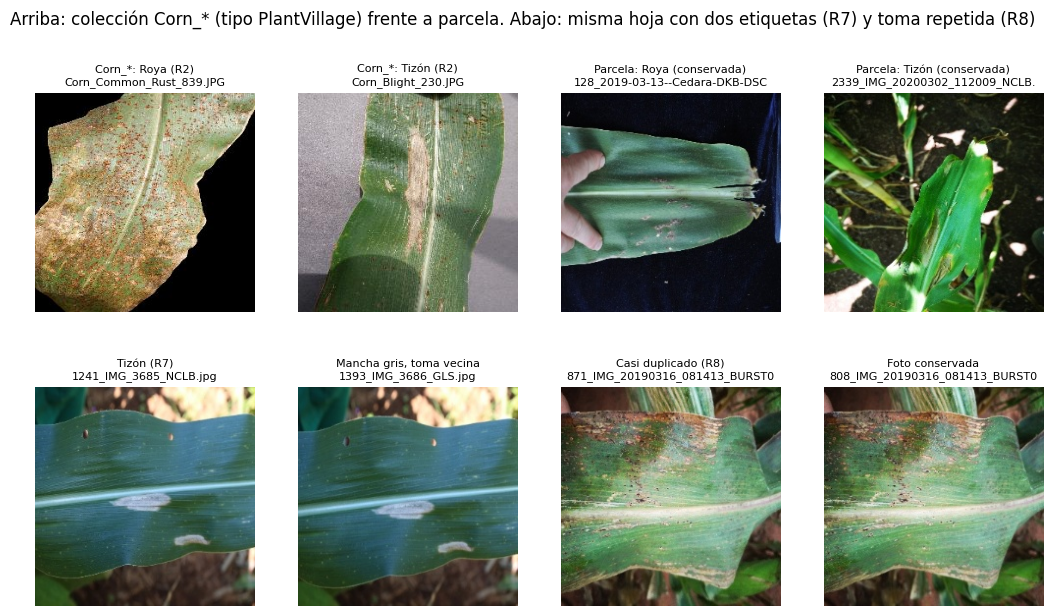

In [8]:
from PIL import Image as Imagen
from obtener_datos import carpeta_imagenes

r7 = registro[registro["regla"] == "R7 conflicto_entre_tomas"].iloc[1]
r8 = registro[registro["regla"] == "R8 casi_duplicado"].iloc[0]
import random
from obtener_datos import rutas_a_descargar

azar = random.Random(42)                       # ejemplos al azar (con semilla), no elegidos a mano
muestra_pv = [r for r in rutas_a_descargar(manifiesto) if r.split("/")[-1].startswith("Corn_")]
pv = [azar.choice([r for r in muestra_pv if r.split("/")[1] == c]) for c in ("CommonRust", "CornLeafBlight")]
parc = [azar.choice(limpio[limpio["clase"] == c]["ruta"].tolist()) for c in ("Roya común", "Tizón")]
ejemplos = [(pv[0], "Corn_*: Roya (R2)"), (pv[1], "Corn_*: Tizón (R2)"),
            (parc[0], "Parcela: Roya (conservada)"), (parc[1], "Parcela: Tizón (conservada)"),
            (r7["ruta"], f"{CARPETA_CLASE[r7['carpeta']]} (R7)"),
            (r7["relacionada_con"], f"{CARPETA_CLASE[r7['relacionada_con'].split('/')[1]]}, toma vecina"),
            (r8["ruta"], "Casi duplicado (R8)"), (r8["relacionada_con"], "Foto conservada")]
carpeta = carpeta_imagenes([r for r, _ in ejemplos])
fig, axs = plt.subplots(2, 4, figsize=(13, 7))
for ax, (ruta, titulo) in zip(axs.flat, ejemplos):
    ax.imshow(Imagen.open(carpeta / ruta))
    ax.set_title(f"{titulo}\n{ruta.split('/')[-1][:30]}", fontsize=8)
    ax.axis("off")
fig.suptitle("Arriba: colección Corn_* (tipo PlantVillage) frente a parcela. Abajo: misma hoja con dos etiquetas (R7) y toma repetida (R8)")
guardar(fig, "datos_6_ejemplos.png")

**Lectura.** Arriba se ve la diferencia de dominio: en la colección `Corn_*` la hoja ocupa casi todo el cuadro, muchas veces sobre un fondo uniforme, mientras que en parcela cambian el encuadre, el fondo y la luz: la roya de la sesión de Cedara (13 de marzo de 2019) es una hoja sostenida en la mano frente a un fondo oscuro, y el tizón está en la planta, con suelo y sombras. Esa diferencia de fondo entre sesiones es justo la que un modelo puede aprender como atajo (sección 4). Los ejemplos se eligen al azar con semilla, no a mano. En la muestra de 400 `Corn_*` también hay algunas fotos de campo, pero son minoría. Abajo, la regla R7 encontró dos tomas consecutivas de la misma hoja guardadas en carpetas distintas, que es el mismo problema de R4 pero con archivos diferentes, por lo que el sha256 no lo detecta. La regla R8 encontró una toma repetida casi idéntica, que habría quedado a la vez en entrenamiento y en validación.

## 2. Diseño del entrenamiento

- **Prueba final:** 20 % del dataset (un fold de `StratifiedGroupKFold`), que no se usa hasta evaluar el modelo elegido.
- **Validación cruzada del Grid Search:** `StratifiedGroupKFold` de 5 folds. Mantiene la proporción de clases y no separa fotos de la misma planta (columna `grupo`), para que una toma casi igual no quede en entrenamiento y otra en validación.
- **Métrica de selección:** F1 macro. También se registran exactitud balanceada, exactitud, F1 por clase y la tasa de hojas enfermas clasificadas como sanas.
- La justificación de cada rejilla está en el README (sección 5).

In [9]:
import train

for nombre, (estimador, rejilla, _) in train.modelos().items():
    print(f"{nombre}: {estimador}")
    for parametro, valores in rejilla.items():
        print(f"    {parametro.split('__')[-1]}: {valores}")
datos, columnas = train.cargar_datos()
entrenamiento, prueba = train.separar_prueba(datos)
pd.DataFrame({"entrenamiento": entrenamiento["clase"].value_counts(),
              "prueba": prueba["clase"].value_counts()}).loc[ORDEN]

regresion_logistica: Pipeline(steps=[('escala', StandardScaler()),
                ('modelo', LogisticRegression(max_iter=5000, random_state=42))])
    C: [0.0001, 0.001, 0.01, 0.1, 1.0]
    class_weight: [None, 'balanced']
random_forest: RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=42)
    min_samples_leaf: [1, 3, 5, 10, 20]
    max_features: ['sqrt', 0.1, 0.25]
    class_weight: [None, 'balanced_subsample']


,entrenamiento,prueba
clase,,
Sana,178,45
Mancha gris,494,120
Tizón,103,30
Roya común,82,26


## 3. Resultados registrados en MLflow

Se leen del experimento `maiz-logreg-vs-rf`: la corrida de comparación más reciente apunta a las corridas de cada modelo. Si no existe `mlflow.db` (por ejemplo, en Colab sin reentrenar) se usa la copia `evidencias/corridas_mlflow.csv`.

In [10]:
import mlflow
from mlflow.tracking import MlflowClient

HAY_MLFLOW = (RAIZ / "mlflow.db").exists() or "MLFLOW_TRACKING_URI" in os.environ
if HAY_MLFLOW:
    train.configurar_mlflow(train.EXPERIMENTO)
    corridas = mlflow.search_runs(experiment_names=[train.EXPERIMENTO])
else:
    corridas = pd.read_csv(RAIZ / "evidencias" / "corridas_mlflow.csv")
corridas = corridas.sort_values("start_time", ascending=False)
comparacion = corridas[corridas["tags.etapa"] == "comparacion"].iloc[0]
MODELOS = ["regresion_logistica", "random_forest"]
padre = {n: corridas[corridas["run_id"] == comparacion[f"params.run_id_{n}"]].iloc[0] for n in MODELOS}
hijas = {n: corridas[corridas["tags.mlflow.parentRunId"] == padre[n]["run_id"]] for n in MODELOS}

def fila(n):
    p = padre[n]
    mejores = {k.replace("params.mejor_", ""): v for k, v in p.items() if k.startswith("params.mejor_") and pd.notna(v)}
    return {"modelo": n, "combinaciones": len(hijas[n]), "mejores hiperparámetros": mejores,
            "CV F1 macro": f"{p['metrics.cv_f1_macro_media']:.3f} ± {p['metrics.cv_f1_macro_std']:.3f}",
            "brecha entrenamiento-CV": round(p["metrics.brecha_entrenamiento_cv"], 3),
            "prueba F1 macro": round(p["metrics.prueba_f1_macro"], 3),
            "prueba exactitud balanceada": round(p["metrics.prueba_balanced_accuracy"], 3),
            "prueba enferma como sana": round(p["metrics.prueba_enferma_como_sana"], 3),
            "tiempo Grid Search (s)": round(p["metrics.tiempo_grid_search_s"]),
            "tamaño del modelo (KB)": round(p["metrics.tamano_modelo_kb"])}

pd.set_option("display.max_colwidth", 120)
pd.DataFrame([fila(n) for n in MODELOS]).set_index("modelo").T

modelo,regresion_logistica,random_forest
combinaciones,10,30
mejores hiperparámetros,"{'class_weight': 'None', 'C': '0.1'}","{'class_weight': 'balanced_subsample', 'max_features': '0.1', 'min_samples_leaf': '10'}"
CV F1 macro,0.665 ± 0.042,0.632 ± 0.048
brecha entrenamiento-CV,0.335,0.28
prueba F1 macro,0.721,0.66
prueba exactitud balanceada,0.703,0.66
prueba enferma como sana,0.114,0.136
tiempo Grid Search (s),7,312
tamaño del modelo (KB),81,3602


In [11]:
f1_clase = pd.DataFrame({n: {c: padre[n][f"metrics.prueba_f1_{train.CLASES[c]}"] for c in ORDEN} for n in MODELOS})
print("F1 por clase en prueba:")
f1_clase.round(3)

F1 por clase en prueba:


,regresion_logistica,random_forest
Sana,0.602,0.606
Mancha gris,0.815,0.774
Tizón,0.588,0.621
Roya común,0.880,0.640


In [12]:
for n in MODELOS:
    params = [c for c in hijas[n].columns if c.startswith("params.") and hijas[n][c].notna().any()]
    mejores = hijas[n].sort_values("metrics.cv_f1_macro_media", ascending=False)
    print(f"\n{n}: 5 mejores de {len(mejores)} combinaciones (corridas hijas)")
    display(mejores[params + ["metrics.cv_f1_macro_media", "metrics.cv_f1_macro_std",
                              "metrics.entrenamiento_f1_macro_media"]].head(5).round(3))


regresion_logistica: 5 mejores de 10 combinaciones (corridas hijas)


,params.class_weight,params.C,metrics.cv_f1_macro_media,metrics.cv_f1_macro_std,metrics.entrenamiento_f1_macro_media
35,None,0.1,0.665,0.042,1.000
36,balanced,0.01,0.662,0.043,0.963
37,None,0.01,0.657,0.030,0.973
33,None,1.0,0.656,0.040,1.000
34,balanced,0.1,0.656,0.046,1.000



random_forest: 5 mejores de 30 combinaciones (corridas hijas)


,params.max_features,params.class_weight,params.min_samples_leaf,metrics.cv_f1_macro_media,metrics.cv_f1_macro_std,metrics.entrenamiento_f1_macro_media
7,0.1,balanced_subsample,10,0.632,0.048,0.912
12,sqrt,balanced_subsample,10,0.628,0.046,0.896
2,0.25,balanced_subsample,10,0.626,0.033,0.924
6,0.1,balanced_subsample,20,0.625,0.045,0.798
11,sqrt,balanced_subsample,20,0.621,0.050,0.778


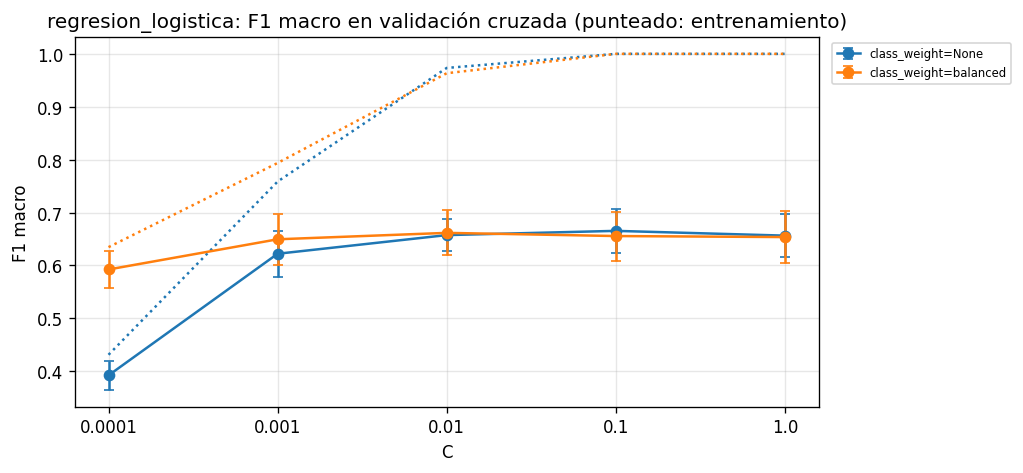

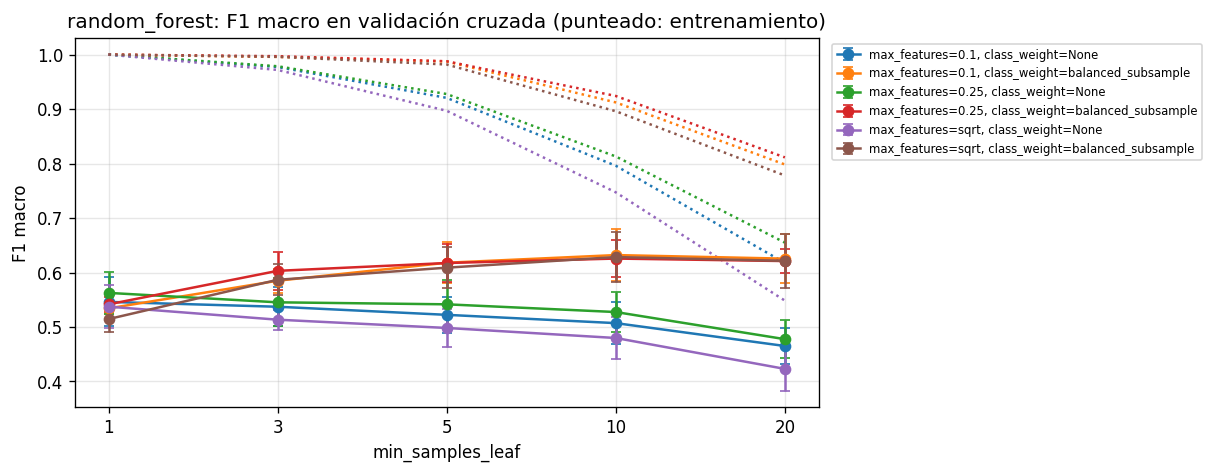

In [13]:
for nombre in ("rejilla_regresion_logistica.png", "rejilla_random_forest.png"):
    display(Image(FIGURAS / nombre))

**Lectura.**

- **Regresión logística.** Con C ≤ 0.001 el modelo está sobre-regularizado, y ahí compensar el desbalance ayuda mucho: con C = 0.0001 da 0.59 con balanceo y 0.39 sin él. Desde C = 0.01 la validación se estabiliza alrededor de 0.66 mientras el F1 de entrenamiento llega a 1.0, o sea, el modelo memoriza el entrenamiento sin ganar en validación. Las seis mejores combinaciones quedan entre 0.654 y 0.665, una diferencia menor que la desviación entre folds (0.04). El Grid Search eligió C = 0.1 sin balanceo (0.665 ± 0.042). Con la regla de un error estándar (umbral 0.665 − 0.042/√5 = 0.646) se habría elegido C = 0.001 con balanceo (0.650), que rinde estadísticamente igual y memoriza mucho menos (F1 de entrenamiento 0.79). No se cambió la regla después de ver los resultados; queda como acción en la sección 5.
- **Random forest.** `max_features` casi no cambia el resultado; lo que importa es `min_samples_leaf` combinado con el balanceo. Con `balanced_subsample`, el F1 sube de ≈ 0.53 con hojas de una sola foto (árboles que memorizan) a 0.632 con 10 fotos por hoja, y baja un poco con 20, así que el óptimo queda dentro de la rejilla ampliada. Sin balanceo pasa lo contrario: regularizar más empuja al bosque hacia la clase mayoritaria y el F1 macro cae hasta 0.42.

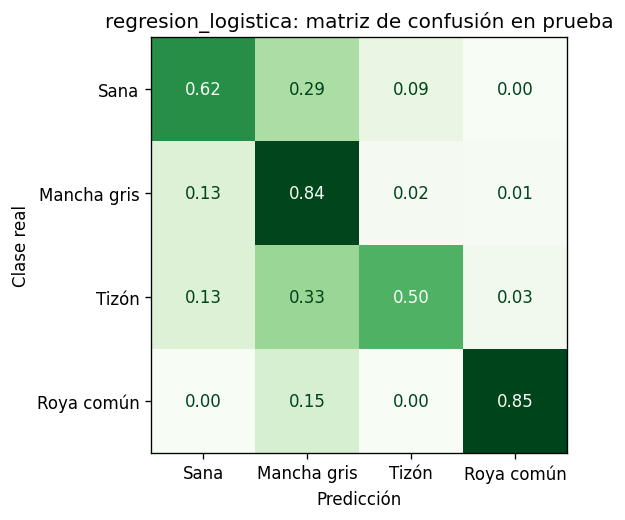

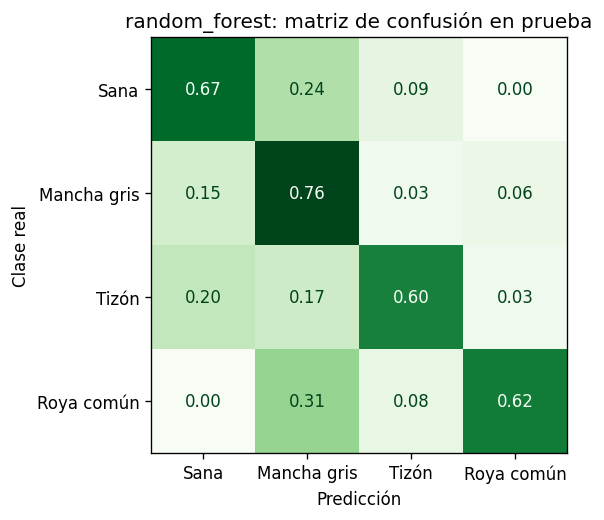

In [14]:
for n in MODELOS:
    display(Image(FIGURAS / f"matriz_confusion_{n}.png", width=420))

**Lectura.** En prueba (221 fotos), la regresión logística reconoce bien Mancha gris (84 %) y Roya (85 %), pero solo el 62 % de Sana y el 50 % de Tizón. El error dominante va hacia Mancha gris: el 29 % de las sanas y el 33 % de los tizones se predicen como Mancha gris, que es la clase mayoritaria y la de lesiones alargadas más parecidas al tizón. El bosque reparte el error de otra forma (mejor en Tizón, 60 %; peor en Roya, 62 %), pero su F1 macro es menor (0.660 frente a 0.721). En los dos, entre 11 y 14 % de las hojas enfermas salen como sanas.

La prueba da un F1 algo mayor que la validación cruzada (0.721 frente a 0.665). Con 221 fotos, y solo 26 de Roya y 30 de Tizón, esa diferencia cabe dentro de la variación entre folds, así que la estimación más estable es la de validación cruzada.

## 4. Comparación estadística y evaluación por sesión

**Prueba estadística.** Los dos modelos, con sus mejores hiperparámetros, se evalúan en los mismos 25 folds (5 repeticiones de `StratifiedGroupKFold` de 5 con semillas distintas), así que los puntajes son pareados. Se reportan dos pruebas:

- **Wilcoxon de rangos con signo:** no paramétrica, pero supone que las 25 diferencias son independientes, y no lo son, porque los folds comparten fotos de entrenamiento.
- **t pareada corregida de Nadeau y Bengio:** corrige esa dependencia inflando la varianza por el factor (1/k + n_prueba/n_entrenamiento). Es la que se usa para decidir, con α = 0.05.

**Sesión fuera.** Con todo el dataset y los mismos hiperparámetros se compara la validación cruzada por grupos con `LeaveOneGroupOut` por sesión: cada sesión se predice con un modelo que no vio ninguna foto de ese día o cámara. Es la situación real de la app, que siempre recibe fotos de un día nuevo.

In [15]:
c = comparacion
resumen = pd.DataFrame({n: {"CV repetida 5x5 (media ± desv.)": f"{c[f'metrics.rep_f1_macro_media_{n}']:.3f} ± {c[f'metrics.rep_f1_macro_std_{n}']:.3f}",
                            "CV por grupos, todo el dataset": round(c[f"metrics.cv_grupos_f1_macro_{n}"], 3),
                            "Sesión fuera (LeaveOneGroupOut)": round(c[f"metrics.sesion_out_f1_macro_{n}"], 3),
                            "Caída por sesión": round(c[f"metrics.sesion_out_f1_macro_{n}"] - c[f"metrics.cv_grupos_f1_macro_{n}"], 3),
                            "Enferma como sana, sesión fuera": round(c[f"metrics.sesion_out_enferma_como_sana_{n}"], 3)}
                        for n in MODELOS})
print(f"Diferencia media (logística - bosque): {c['metrics.diferencia_media']:+.3f}  "
      f"IC 95 % corregido [{c['metrics.diferencia_ic95_inf']:+.3f}, {c['metrics.diferencia_ic95_sup']:+.3f}]")
print(f"Folds ganados por la logística: {int(c['metrics.victorias_regresion_logistica'])} de {train.REPETICIONES * train.N_FOLDS}")
print(f"t corregida = {c['metrics.t_corregida']:.2f}, p = {c['metrics.p_t_corregida']:.4f} | Wilcoxon p = {c['metrics.p_wilcoxon']:.2g}")
print(f"Decisión: {c['tags.ganador']} ({c['tags.razon_decision']})")
resumen

Diferencia media (logística - bosque): +0.023  IC 95 % corregido [-0.020, +0.066]
Folds ganados por la logística: 20 de 25
t corregida = 1.11, p = 0.2782 | Wilcoxon p = 0.0046
Decisión: regresion_logistica (sin diferencia significativa (p corregida = 0.2782); se elige el modelo más ligero)


,regresion_logistica,random_forest
CV repetida 5x5 (media ± desv.),0.649 ± 0.035,0.626 ± 0.035
"CV por grupos, todo el dataset",0.683,0.644
Sesión fuera (LeaveOneGroupOut),0.425,0.428
Caída por sesión,-0.258,-0.216
"Enferma como sana, sesión fuera",0.137,0.145


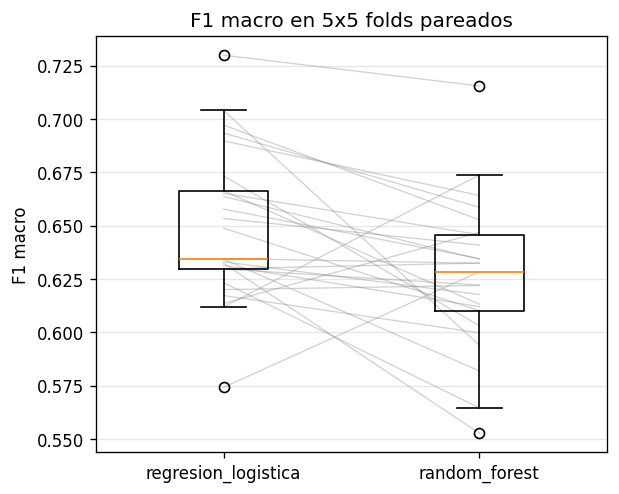

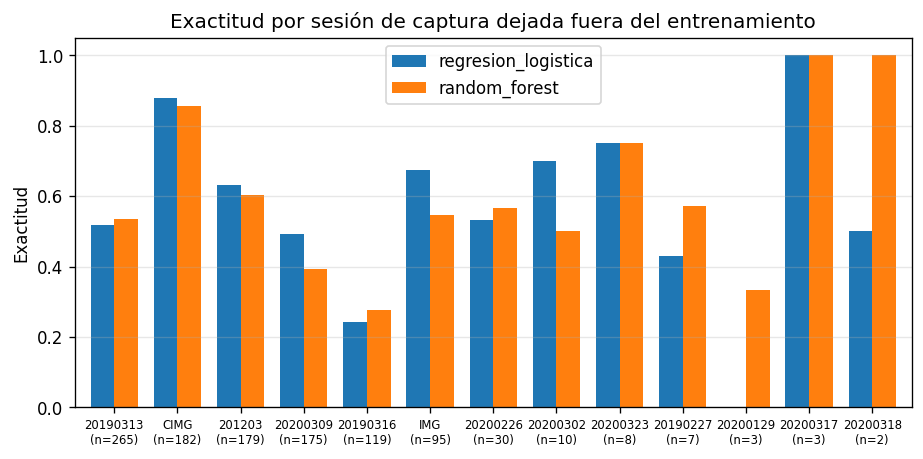

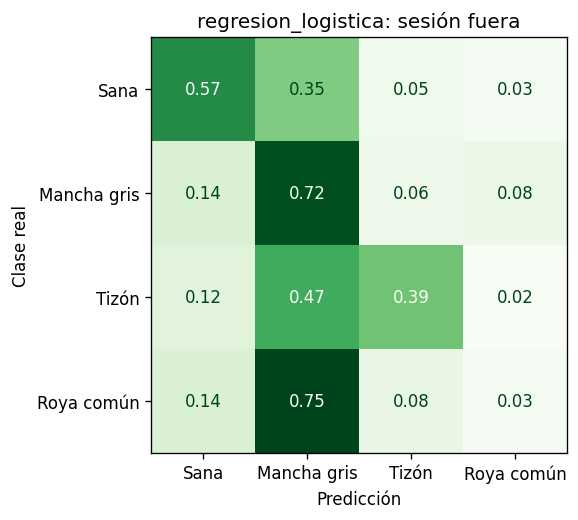

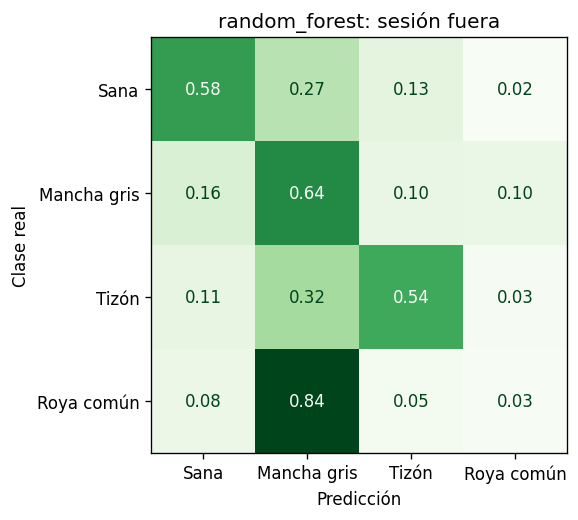

In [16]:
display(Image(FIGURAS / "comparacion_cv_repetida.png", width=430))
display(Image(FIGURAS / "acierto_por_sesion.png"))
for n in MODELOS:
    display(Image(FIGURAS / f"matriz_sesion_out_{n}.png", width=420))

**Prueba estadística.** La regresión logística gana en 20 de 25 folds, con una diferencia media de +0.023 de F1 macro. Wilcoxon da p = 0.005 y parecería significativo, pero trata como independientes 25 folds que comparten fotos de entrenamiento. La t corregida de Nadeau y Bengio da p = 0.28, y su intervalo de 95 % para la diferencia, [−0.020, +0.066], incluye el cero: **no hay evidencia suficiente para afirmar que un modelo es mejor que el otro**. Por la regla fijada antes de ver los resultados gana el más ligero: la regresión logística pesa 81 KB contra 3.6 MB del bosque (44 veces menos), y su Grid Search tardó 8 s contra 6 min.

**Sesión fuera: el hallazgo principal.** Con validación por grupos los modelos llegan a F1 macro de 0.68 y 0.64. Cuando cada sesión completa queda fuera del entrenamiento, los dos caen a 0.43, prácticamente el 0.41 de la Actividad 4. La matriz explica por qué: **Roya pasa de ser la clase mejor reconocida (F1 0.88 en prueba) a casi no detectarse (F1 0.04)**, y el 75 % de las royas se predicen como Mancha gris.

El 69 % de las fotos de roya viene de una sola sesión, el 16 de marzo de 2019 (ver 1.4). Pero la cantidad no es la única causa: cuando la sesión del 13 de marzo queda fuera, el modelo sí vio las 75 royas del 16 de marzo, y aun así 22 de las 30 royas del 13 de marzo salen como Mancha gris. El modelo aprendió las condiciones de captura de esa sesión más que la pústula de la roya. Por sesión, la del 16 de marzo tiene la exactitud más baja (24 %), mientras que `CIMG` llega a 88 % solo porque casi todas sus fotos son de Mancha gris, la clase hacia la que el modelo se inclina. En esta evaluación los dos algoritmos empatan (0.425 frente a 0.428): **la limitación no está en el algoritmo sino en los datos**.

### Modelo registrado

In [17]:
if HAY_MLFLOW:
    cliente = MlflowClient()
    version = cliente.get_model_version_by_alias(train.MODELO_REGISTRADO, "candidato")
    modelo = mlflow.sklearn.load_model(f"models:/{train.MODELO_REGISTRADO}@candidato")
    pred = modelo.predict(prueba[columnas])
    f1 = train.metricas(prueba["clase"], pred, "prueba")["prueba_f1_macro"]
    print(f"{train.MODELO_REGISTRADO} v{version.version} (alias candidato): {version.tags['algoritmo']}")
    print(f"F1 macro en prueba al recargarlo: {f1:.4f} | registrado: {version.tags['prueba_f1_macro']}")
else:
    print("Sin mlflow.db: corre el notebook con REENTRENAR = True para recrear el registro.")

clasificador-hoja-maiz v1 (alias candidato): regresion_logistica
F1 macro en prueba al recargarlo: 0.7212 | registrado: 0.7212


**Lectura.** El modelo se recarga desde el Model Registry por su alias y reproduce exactamente el F1 de prueba registrado. Queda como `candidato` y no como `produccion`: con F1 macro de 0.43 en sesiones nuevas y la roya casi sin detectar, todavía no sirve para recomendar tratamientos en campo.

## 5. Deuda técnica y acciones MLOps

| Deuda técnica | Tipo | Evidencia en este proyecto | Acción MLOps propuesta | Prioridad |
|---|---|---|---|---|
| Atajo por sesión de captura | Datos | El F1 macro baja de 0.68 a 0.43 con la sesión fuera; la roya, de 0.88 a 0.04; los vecinos comparten sesión 3.8 veces más que al azar | Protocolo de captura en que cada salida a campo fotografíe todas las clases; adoptar la evaluación con la sesión fuera como métrica oficial y como condición para promover un modelo de `candidato` a `produccion` | Alta |
| Etiquetas con varias enfermedades | Datos | 1,121 fotos excluidas por R4 y R7; Tizón pierde el 76 % de sus fotos | Re-etiquetado multietiqueta (todas las enfermedades presentes), revisado por un agrónomo y con guía de etiquetado; evaluar un modelo multietiqueta | Alta |
| Datos de terceros sin licencia | Gobernanza | El repositorio de origen no declara licencia; las imágenes no se pueden redistribuir | Construir el dataset propio con la asociación, con consentimiento y licencia explícitos; versionar las imágenes con DVC en almacenamiento propio; ficha del dataset | Alta |
| Extractor de características externo | Dependencias | MobileNetV2 de un repositorio personal de Hugging Face; transformers 5 cambiaba de backend según torchvision, y con él las características | Guardar los pesos del extractor como artefacto propio en MLflow; prueba automática que recalcule las características de una muestra y compare su sha256 | Media |
| Métrica de negocio sin optimizar | Modelo | Entre 11 y 14 % de las hojas enfermas salen como sanas | Calibrar las probabilidades y fijar un umbral para "Sana" que limite ese error; registrar el costo esperado junto al modelo | Media |
| Seguimiento local no compartido | Infraestructura | `mlflow.db` y `mlruns/` guardan rutas absolutas y no se suben; la evidencia se exporta a CSV | Servidor de MLflow remoto con almacenamiento de artefactos (S3 o MinIO) y control de acceso | Media |
| Pipeline manual sin integración continua | Infraestructura | Tres scripts que se ejecutan a mano y en orden | Pipeline declarativo (etapas de DVC o Makefile) y GitHub Actions que validen los datos, corran `train.py --validar` y comprueben que el dataset regenera la misma `datos_sha256` | Media |
| Sin validación de entrada ni monitoreo | Operación | La app recibirá fotos fuera de distribución: las `Corn_*` forman un grupo aparte en el espacio de características | Validar la calidad de cada foto al ingresar; detector de fuera de distribución por distancia en el espacio de características; monitoreo del desempeño por sesión y por región | Media |
| Sobreajuste de la regresión logística | Modelo | F1 de entrenamiento 1.0 frente a 0.665 en validación; C = 0.001 con balanceo rinde dentro de un error estándar con F1 de entrenamiento 0.79 | Seleccionar con la regla de un error estándar; alerta cuando la brecha entre entrenamiento y validación pase un umbral | Baja |
| Dependencias y serialización del modelo | Modelo | La inferencia de MLflow agregó torch, dill y tqdm; skops rechazó los árboles por seguridad | Requisitos explícitos (ya aplicado); probar el modelo servido en un entorno limpio dentro de la integración continua; cargar modelos solo del registro propio y verificar el hash del artefacto | Baja |

Las dos primeras filas son la causa de fondo del 0.43 y del 0.41 de la Actividad 4: ningún cambio de algoritmo las resuelve. El siguiente paso con más valor no es otro modelo, sino una campaña de captura y etiquetado con la asociación, diseñada para romper la relación entre sesión y clase.